# How far ahead to trust a customer's plan

A customer sends a supply plan every week covering the months ahead. Our lead time is three to four months. The question is which plan to commit production against: the freshest one, or the one written when we could still act on it?

Each target month is scored against the plan held one to five months earlier. The actual orders are one fixed number per month, so every row measures a plan and nothing else. This is the analysis behind the write-up *How much of a customer's plan to trust*.

> Clean-room version. The customer, the items and every number are generated.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

import pandas as pd

from supply_ops import plan_accuracy, synthetic
from supply_ops.plots import horizon_curve

snapshots, orders = synthetic.plan_snapshots()
months = [pd.Period("2026-05"), pd.Period("2026-06"), pd.Period("2026-07")]
print(f"{snapshots['received'].nunique()} weekly plans, {snapshots['item'].nunique()} items planned, "
      f"{orders['item'].nunique()} items ordered, target months {', '.join(map(str, months))}")

30 weekly plans, 120 items planned, 125 items ordered, target months 2026-05, 2026-06, 2026-07


## 1. Score every horizon

Gap = (actual orders - plan) / plan, summed over items. Positive means the customer ordered more than it planned. Each month is scored against the first plan received in the earlier month.

In [2]:
first = plan_accuracy.horizon_table(snapshots, orders, months, anchor="first")
last = plan_accuracy.horizon_table(snapshots, orders, months, anchor="last")
shown = first.copy()
for c in [str(m) for m in months]:
    shown[c] = shown[c].map("{:+.1%}".format)
shown["average_miss"] = shown["average_miss"].map("{:.1%}".format)
shown

,months_ahead,2026-05,2026-06,2026-07,average_miss,months_scored
0,1,+16.0%,+23.0%,+25.3%,21.4%,3
1,2,+10.8%,+10.2%,+13.8%,11.6%,3
2,3,+4.4%,-1.4%,+11.3%,5.7%,3
3,4,+0.4%,+3.3%,+7.2%,3.6%,3
4,5,-7.3%,-5.5%,-3.1%,5.3%,3


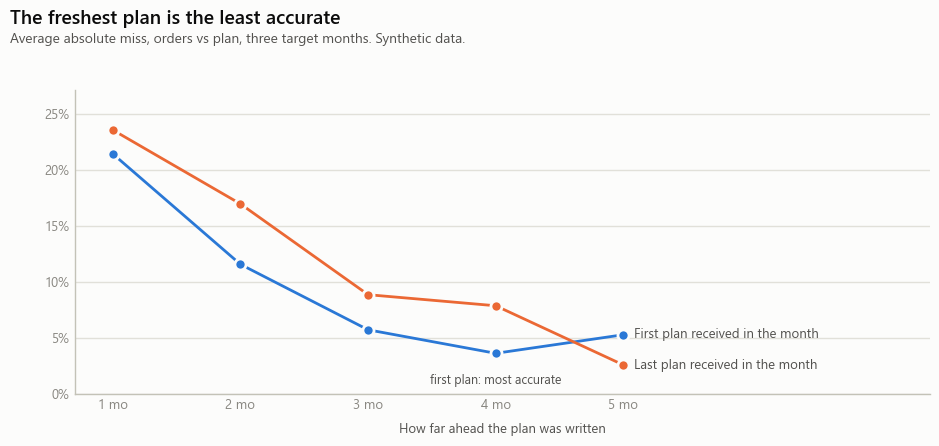

In [3]:
horizon_curve(first, last, path=ROOT / "images" / "plan_horizon.png");

## 2. Which plan counts as "the plan four months ahead"?

Several plans arrive in each month. Taking the first one or the last one changes the numbers, and can change how large the gap between horizons looks. Pick one before looking, write it down, and lead with the smaller difference.

In [4]:
both = first[["months_ahead", "average_miss"]].merge(
    last[["months_ahead", "average_miss"]], on="months_ahead", suffixes=("_first_plan", "_last_plan"))
for c in ("average_miss_first_plan", "average_miss_last_plan"):
    both[c] = both[c].map("{:.1%}".format)
both

,months_ahead,average_miss_first_plan,average_miss_last_plan
0,1,21.4%,23.6%
1,2,11.6%,17.0%
2,3,5.7%,8.9%
3,4,3.6%,7.9%
4,5,5.3%,2.6%


## 3. An inner join would have hidden part of the gap

Some items are ordered without ever appearing in a plan. An inner join drops them silently and makes the plan look better than it was.

In [5]:
m = pd.Period("2026-07")
held = plan_accuracy.plan_held(snapshots, m, 1)
outer = plan_accuracy.gap(held, orders, m)
inner = plan_accuracy.gap(held, orders, m, join="inner")
print(f"July, plan one month ahead. Outer join: {outer:+.1%}. Inner join: {inner:+.1%}.")

July, plan one month ahead. Outer join: +25.3%. Inner join: +22.0%.


## Key findings

- The freshest plan is the least accurate: in the final weeks before a month, the plan is cut, and cut too far.
- Both anchors agree that the nearest plan is the worst; they disagree on the details further out. The anchor is chosen and stated before the result, and the smaller difference is the one reported.
- Production is committed against the plan held at the lead time and is not re-cut when a late plan drops. The plan is read as a direction for total volume; item-level supply comes from our own forecast.
- Only three months have complete actuals here, so this is a direction, not a settled rule.